# Módulo 7: lineups

**Preguntas:**
- **E.** ¿El net rating de un lineup en la primera mitad de la temporada predice el de la segunda?
- ¿Cuánta de esa persistencia es del lineup y cuánta es simplemente la fuerza de su equipo?
- ¿Cuánto hay que creerle al net rating de un lineup de 5 jugadores (error de muestreo, ranking)?

**Diseño (decidido antes de ver los datos):**
- 2025-26. Dividir las fechas de la temporada en dos mitades (cronológico, nunca mezclar): la primera predice la segunda.
- Net rating = puntos anotados menos recibidos por 100 posesiones.
- Error de muestreo del net rating a partir de los márgenes reales de los partidos: `SD_margen × √(100 / posesiones)`.
- Encogimiento del rating del lineup hacia el de su equipo: `(net × posesiones + equipo × k) / (posesiones + k)`, con k elegido por error de predicción de la segunda mitad.
- Comparaciones con intervalos (bootstrap sobre lineups), no solo promedios.

**Mi hipótesis previa (E):** ninguna ("sin intuición, corre"). La referencia es "no persiste" (correlación 0).

Para reproducir: `python -m uv run jupyter lab`; los datos salen de la caché local.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sportslab.analysis.lineups import (
    add_uncertainty,
    margin_sd_per_game,
    paired_error_gain,
    paired_halves,
    persistence,
    prediction_errors,
)
from sportslab.data import NbaClient
from sportslab.data.games import load_games
from sportslab.data.lineups import load_lineups, load_team_ratings

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.1f}".format
pd.options.display.width = 200

client = NbaClient()
SEASON = "2025-26"
MIN_POSS = 300
KS = (0, 100, 200, 400, 800, 1600, 3200, 1_000_000)

games = load_games(client, [SEASON])
dates = sorted(games["game_date"].dt.date.unique())
mid = len(dates) // 2
first_to, second_from = dates[mid - 1], dates[mid]
margin_sd = margin_sd_per_game(games)
team_first = load_team_ratings(client, SEASON, date_to=first_to)
print(
    f"{SEASON}: mitades separadas el {second_from}; desviación del margen por partido {margin_sd:.1f}"
)

2025-26: mitades separadas el 2026-01-14; desviación del margen por partido 16.4


## 0. Tres hallazgos de datos antes de empezar

1. **NBA.com entrega solo los 2000 lineups con más minutos.** Los de 5 jugadores se cortan en 12 minutos y cubren ~54 % de los minutos de la liga. Todo lo siguiente es sobre lineups muy usados.
2. **Los lineups de 5 casi no se repiten entre mitades.** Con ≥ 300 posesiones en *ambas* mitades solo hay 4. Por eso la prueba de persistencia se hace con **parejas** y **tríos**, que sí se repiten (cientos de casos). Cambié el diseño por lo que mostraron los datos; lo dejo escrito.
3. **El mismo grupo de jugadores puede aparecer bajo dos equipos** si uno fue traspasado. La clave de un lineup es (id, equipo); la clave solo por id fallaba con parejas de toda la temporada.

## 1. Lineups de 5 jugadores: ¿cuánto creerle al net rating?

2000 lineups; el más pequeño tiene 12 min; cubren 54% de los minutos de la liga
79 lineups con >= 100 min; error mediano (1 SE): 9.5; intervalos que excluyen 0: 16
Si NINGÚN lineup fuera distinto de 0, esperaríamos ~4 por azar


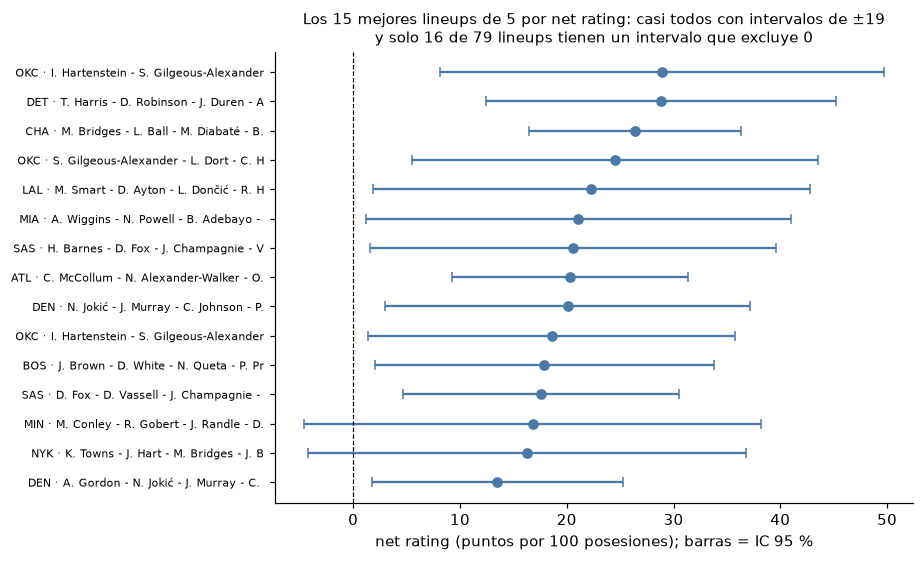

In [2]:
five = load_lineups(client, SEASON, 5)
team_minutes = 30 * 82 * 48
print(
    f"{len(five)} lineups; el más pequeño tiene {five['minutes'].min():.0f} min; "
    f"cubren {five['minutes'].sum() / team_minutes:.0%} de los minutos de la liga"
)
big = add_uncertainty(five[five["minutes"] >= 100], margin_sd)
excl = int(((big["ci_low"] > 0) | (big["ci_high"] < 0)).sum())
print(
    f"{len(big)} lineups con >= 100 min; error mediano (1 SE): {big['se'].median():.1f}; "
    f"intervalos que excluyen 0: {excl}"
)
print(f"Si NINGÚN lineup fuera distinto de 0, esperaríamos ~{0.05 * len(big):.0f} por azar")

top = big.nlargest(15, "net_rating").iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.2))
y = np.arange(len(top))
ax.errorbar(
    top["net_rating"],
    y,
    xerr=[top["net_rating"] - top["ci_low"], top["ci_high"] - top["net_rating"]],
    fmt="o",
    color="#4C78A8",
    capsize=3,
)
ax.set_yticks(
    y, [f"{t} · {p[:38]}" for t, p in zip(top["team"], top["players"], strict=True)], fontsize=7
)
ax.axvline(0, color="k", ls="--", lw=0.8)
ax.set_xlabel("net rating (puntos por 100 posesiones); barras = IC 95 %")
ax.set_title(
    f"Los 15 mejores lineups de 5 por net rating: casi todos con intervalos de ±{1.96 * big['se'].median():.0f}\n"
    f"y solo {excl} de {len(big)} lineups tienen un intervalo que excluye 0",
    fontsize=10,
)
plt.tight_layout()
plt.show()

**Lectura.** Con 100+ minutos (~200 posesiones) el error estándar de un lineup es de ~9.5 puntos, es decir ±19 en el intervalo del 95 %: más grande que casi cualquier diferencia real entre lineups. De 79 lineups, 16 tienen un intervalo que excluye 0 y por puro azar esperaríamos ~4: hay lineups realmente distintos del promedio, pero la mayoría no se distingue. Ordenar por net rating crudo premia a quien tuvo suerte además de a quien es bueno. Un recordatorio contra "el mejor lineup de la liga tiene +26": con esa muestra, el intervalo es enorme.

Nota: el error se calcula con la desviación de los márgenes de partido de toda la temporada, que incluye diferencias reales entre equipos, así que si exagera el ruido lo hace poco.

## 2. ¿Persisten? Parejas y tríos, primera vs segunda mitad

grupos de 2: 799 lineups con >= 300 posesiones en ambas mitades
   Spearman 1.ª vs 2.ª mitad: +0.46 [+0.40, +0.51]
   más allá del equipo:       +0.12 [+0.05, +0.20]


grupos de 3: 397 lineups con >= 300 posesiones en ambas mitades
   Spearman 1.ª vs 2.ª mitad: +0.44 [+0.36, +0.53]
   más allá del equipo:       +0.14 [+0.05, +0.26]


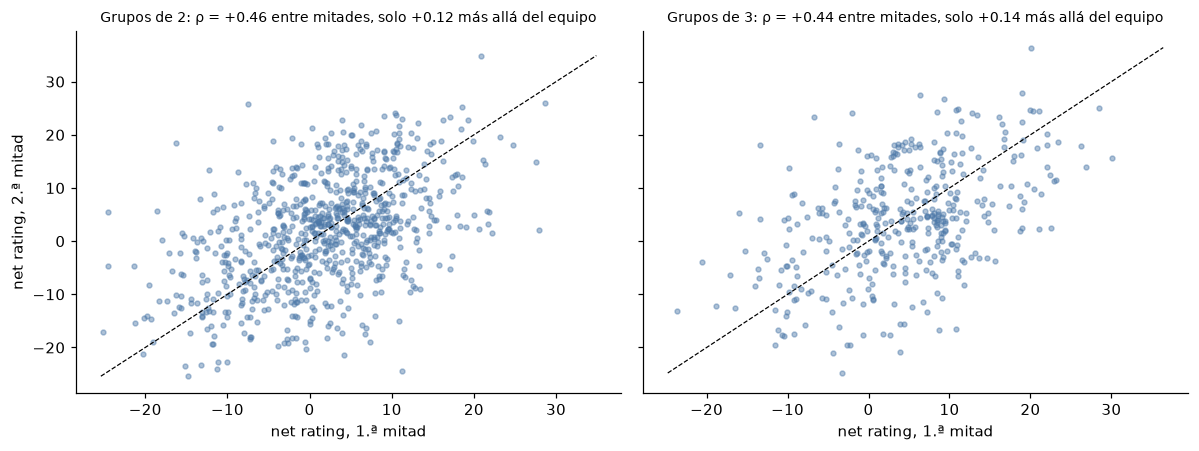

In [3]:
joined, results = {}, {}
for size in (2, 3):
    first = load_lineups(client, SEASON, size, date_to=first_to)
    second = load_lineups(client, SEASON, size, date_from=second_from)
    joined[size] = paired_halves(first, second, team_first, MIN_POSS)
    results[size] = persistence(joined[size])
    r, b = results[size]["raw"], results[size]["beyond_team"]
    print(
        f"grupos de {size}: {len(joined[size])} lineups con >= {MIN_POSS} posesiones en ambas mitades"
    )
    print(f"   Spearman 1.ª vs 2.ª mitad: {r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]")
    print(f"   más allá del equipo:       {b[0]:+.2f} [{b[1]:+.2f}, {b[2]:+.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, size in zip(axes, (2, 3), strict=True):
    j = joined[size]
    ax.scatter(j["net_1"], j["net_2"], s=10, alpha=0.45, color="#4C78A8")
    lim = [min(j["net_1"].min(), j["net_2"].min()), max(j["net_1"].max(), j["net_2"].max())]
    ax.plot(lim, lim, color="k", lw=0.8, ls="--")
    ax.set_xlabel("net rating, 1.ª mitad")
    r = results[size]["raw"]
    ax.set_title(
        f"Grupos de {size}: ρ = {r[0]:+.2f} entre mitades, solo "
        f"{results[size]['beyond_team'][0]:+.2f} más allá del equipo",
        fontsize=9,
    )
axes[0].set_ylabel("net rating, 2.ª mitad")
plt.tight_layout()
plt.show()

**Lectura de E.** Hay persistencia real (ρ ≈ +0.45 con intervalo muy lejos de 0), pero **la mayor parte es el equipo**: al restar el net rating del equipo, queda ρ ≈ +0.12 en parejas y +0.14 en tríos (intervalos que excluyen 0, pero chicos). Un lineup "bueno" lo es sobre todo porque está en un buen equipo.

**Sesgo de selección:** solo entran lineups que siguieron jugando mucho en ambas mitades, y los entrenadores mantienen los que funcionan. La persistencia real de un lineup elegido al azar probablemente es menor.

## 3. Regresión a la media: el mejor decil se desinfla

 grupo  lineups  1.ª mitad  2.ª mitad  equipo (1.ª mitad)  todos, 2.ª mitad
     2       81       16.2        8.9                 6.3               1.7
     3       40       20.4       15.4                 5.9               4.0


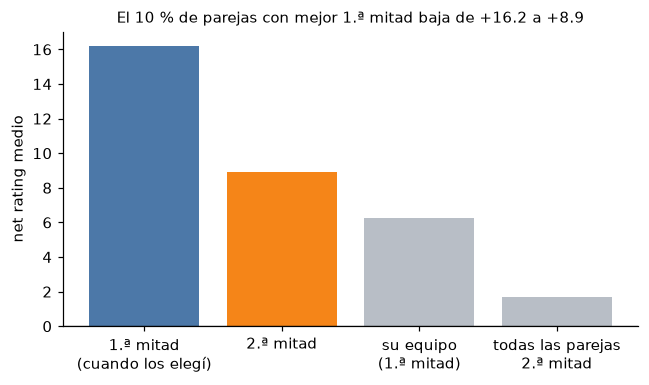

In [4]:
rows = []
for size in (2, 3):
    j = joined[size]
    top = j[j["net_1"] >= j["net_1"].quantile(0.9)]
    rows.append(
        {
            "grupo": size,
            "lineups": len(top),
            "1.ª mitad": top["net_1"].mean(),
            "2.ª mitad": top["net_2"].mean(),
            "equipo (1.ª mitad)": top["team_net_1"].mean(),
            "todos, 2.ª mitad": j["net_2"].mean(),
        }
    )
print(pd.DataFrame(rows).to_string(index=False))

j = joined[2]
top = j[j["net_1"] >= j["net_1"].quantile(0.9)]
fig, ax = plt.subplots(figsize=(6, 3.6))
vals = [top["net_1"].mean(), top["net_2"].mean(), top["team_net_1"].mean(), j["net_2"].mean()]
ax.bar(
    [
        "1.ª mitad\n(cuando los elegí)",
        "2.ª mitad",
        "su equipo\n(1.ª mitad)",
        "todas las parejas\n2.ª mitad",
    ],
    vals,
    color=["#4C78A8", "#F58518", "#B8BEC6", "#B8BEC6"],
)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("net rating medio")
ax.set_title(
    f"El 10 % de parejas con mejor 1.ª mitad baja de {vals[0]:+.1f} a {vals[1]:+.1f}", fontsize=10
)
plt.tight_layout()
plt.show()

Los lineups elegidos por haber sido los mejores de la primera mitad rinden menos en la segunda, y se acercan al rating de su equipo. Es regresión a la media: elegir los extremos selecciona también la suerte.

## 4. Encogimiento: ¿hacia dónde y cuánto?

Predigo el net rating de la segunda mitad con el de la primera acercado hacia (a) el rating de su equipo o (b) 0 (promedio de la liga), con k pseudo-posesiones. k=0 es el crudo; k enorme es solo el prior.

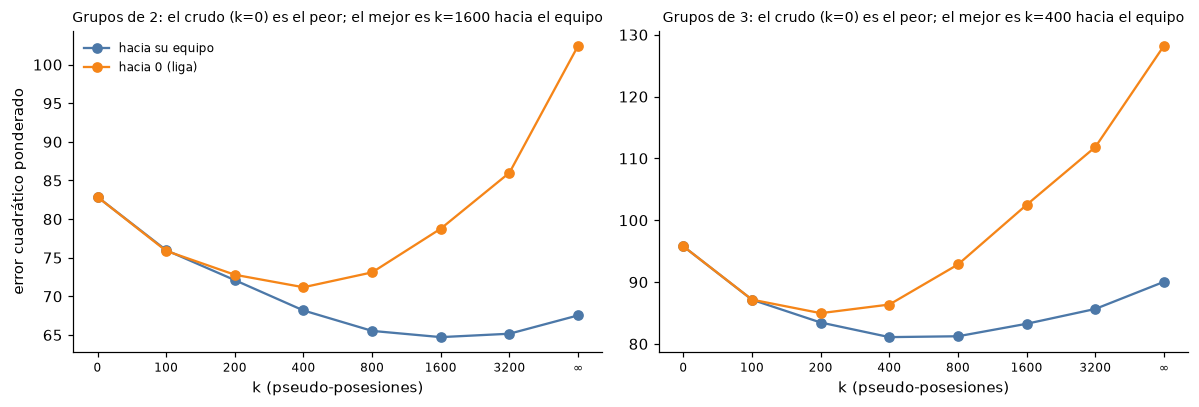

grupos de 2 (mejor k=1600): ganancia sobre el crudo 18.1 [12.7, 23.8]; sobre solo el equipo 2.8 [0.5, 5.3]
grupos de 3 (mejor k=400): ganancia sobre el crudo 14.7 [7.8, 21.5]; sobre solo el equipo 8.9 [-0.5, 18.8]


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, size in zip(axes, (2, 3), strict=True):
    j = joined[size]
    for prior, color in (("team", "#4C78A8"), ("zero", "#F58518")):
        err = prediction_errors(j, KS, prior)
        ax.plot(
            range(len(KS)),
            err.values,
            marker="o",
            color=color,
            label="hacia su equipo" if prior == "team" else "hacia 0 (liga)",
        )
    ax.set_xticks(range(len(KS)), [str(k) if k < 1_000_000 else "∞" for k in KS], fontsize=8)
    err_team = prediction_errors(j, KS, "team")
    best = int(err_team.idxmin())
    ax.set_title(
        f"Grupos de {size}: el crudo (k=0) es el peor; el mejor es k={best} hacia el equipo",
        fontsize=9,
    )
    ax.set_xlabel("k (pseudo-posesiones)")
axes[0].set_ylabel("error cuadrático ponderado")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

for size in (2, 3):
    j = joined[size]
    best = int(prediction_errors(j, KS, "team").idxmin())
    g1 = paired_error_gain(j, 0, best)
    g2 = paired_error_gain(j, 1_000_000, best)
    print(
        f"grupos de {size} (mejor k={best}): ganancia sobre el crudo {g1[0]:.1f} [{g1[1]:.1f}, {g1[2]:.1f}]; "
        f"sobre solo el equipo {g2[0]:.1f} [{g2[1]:.1f}, {g2[2]:.1f}]"
    )

**Lectura.**
- Encoger mejora mucho sobre el crudo en ambos tamaños (intervalos lejos de 0).
- Encoger hacia el **equipo** es mejor que hacia 0: el equipo es información útil que se pierde si uno encoge hacia el promedio de la liga.
- Sobre usar solo el rating del equipo, el lineup aporta una mejora pequeña pero detectable en **parejas** (intervalo que excluye 0) y no distinguible de 0 en tríos. Es decir: el lineup añade poco a lo que ya dice el equipo.
- El k óptimo es grande (cientos de posesiones, más en parejas): un lineup necesita muchas posesiones para que su rating pese más que el del equipo.

**Cautela:** el k de 5 jugadores no se pudo validar (apenas 4 lineups en ambas mitades); en la página uso 400 como valor de partida y lo digo.

## 5. Resultado vs. hipótesis

No hubo hipótesis previa. Contra la referencia "no persiste":

| Pregunta | Resultado 2025-26 | Veredicto |
|---|---|---|
| E. ¿Persiste entre mitades? | ρ ≈ +0.46 (parejas) y +0.44 (tríos), intervalos lejos de 0 | Sí, persiste |
| ¿Es el lineup o el equipo? | Más allá del equipo: +0.12 y +0.14 | Casi todo es el equipo |
| ¿Cuánto creer un net rating crudo? | Error estándar ~9.5 (±19 al 95 %) con ~100 min; 16 de 79 lineups de 5 excluyen 0 | Poco: ordenar por crudo exagera |
| Encogimiento | Mejora sobre crudo (intervalos lejos de 0); sobre solo equipo: pequeña en parejas | Usar valores encogidos hacia el equipo |

**Qué mejorar (no hecho):** una regresión ridge sobre lineups (cada jugador un coeficiente) para separar el aporte individual del de los compañeros, con la advertencia del truncado a 2000 lineups (~54 % de los minutos); datos por posesión (stints) para no perder el 46 % restante; validar con más temporadas.

## 6. Tus ejercicios

1. **Predice y mide.** Cambia `MIN_POSS` a 500. Antes de correr, escribe si esperas que la correlación entre mitades suba o baje, y si el mejor k cambia. Luego mide cuántos lineups quedan y por qué esa pregunta tiene dos respuestas contrarias (menos ruido por lineup vs. selección más fuerte).
2. **Otra temporada.** Repite con 2024-25 (`SEASON = "2024-25"`). Antes de correr, predice si la parte "más allá del equipo" será mayor, menor o igual. Con una sola temporada no se sabe cuánto de lo que viste es de 2025-26.